--- Исходные параметры экспериментального события ---
Истинная Энергия: 1.35 МэВ
Истинные Координаты: X=0.40, Y=-0.30, Z=0.70
Всего зарегистрировано фотоэлектронов: 152
Количество сработавших ФЭУ: 38 из 40

Запуск MCMC-цепей Маркова для реконструкции параметров...


Output()


================ РЕЗУЛЬТАТЫ РЕКОНСТРУКЦИИ ================
Параметр Energy | Истинное:  1.35 | Реконструированное:  1.44 ± 0.122
Параметр X      | Истинное:  0.40 | Реконструированное:  0.34 ± 0.102
Параметр Y      | Истинное: -0.30 | Реконструированное: -0.25 ± 0.107
Параметр Z      | Истинное:  0.70 | Реконструированное:  0.79 ± 0.106


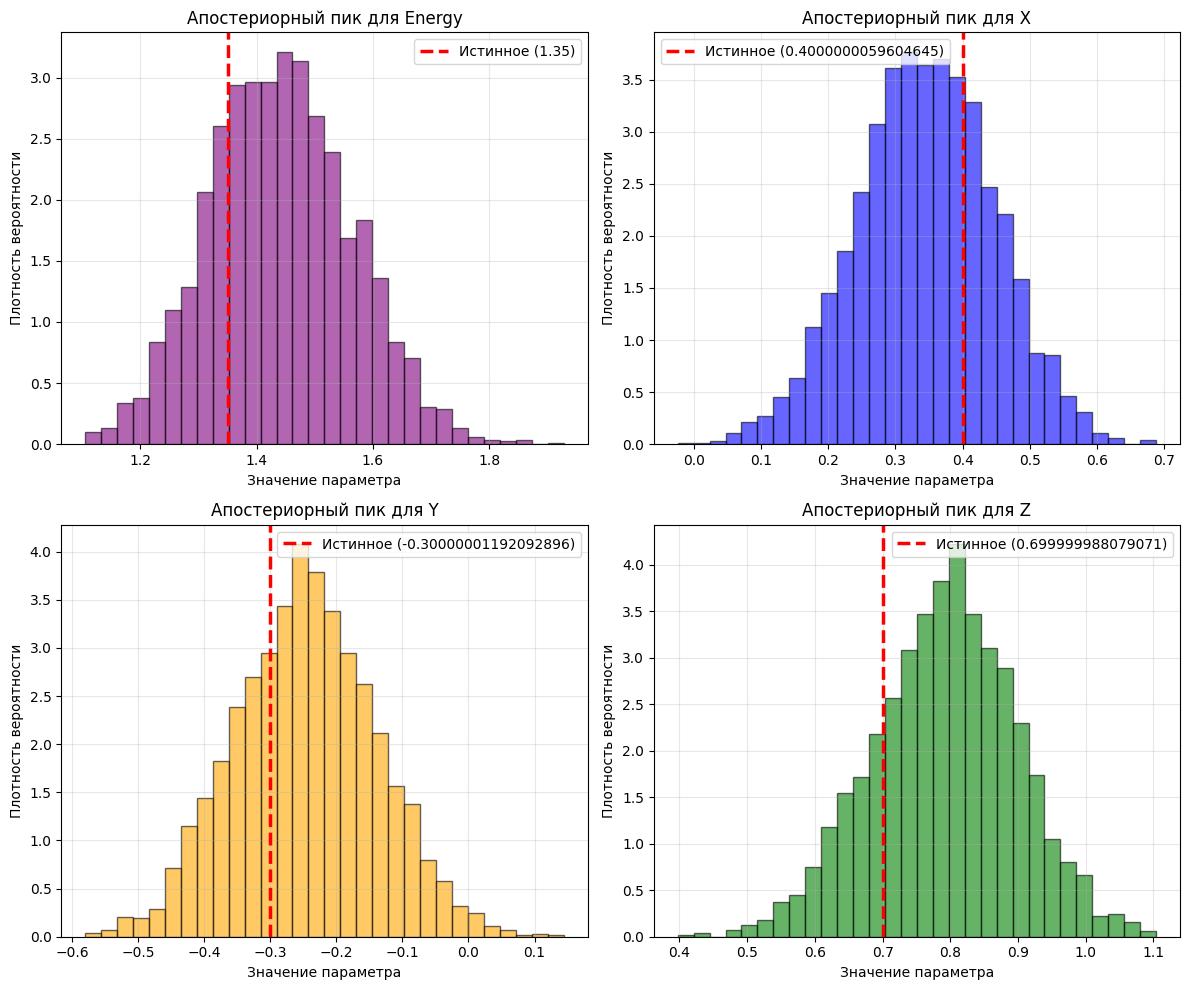

In [ ]:
import numpy as np
import pymc as pm
import matplotlib.pyplot as plt

R = 2.0
N = 40
r_pmt = 0.1
a_eff = 0.5
Y_yield = 10000
lambda_att = 8.0

phi = np.pi * (5.0**0.5 - 1.0)
pmt_pts = []
for i in range(N):
    y_coord = 1 - (i / float(N - 1)) * 2
    radius_at_y = np.sqrt(1 - y_coord * y_coord)
    theta = phi * i
    pmt_pts.append([np.cos(theta) * radius_at_y * R, y_coord * R, np.sin(theta) * radius_at_y * R])
pmt_coordinates = np.array(pmt_pts, dtype=np.float32)

#Генерация наблюдаемого сэмпла (истинные параметры события)
E_true = 1.35
pos_true = np.array([0.4, -0.3, 0.7], dtype=np.float32)

distances_true = np.linalg.norm(pmt_coordinates - pos_true, axis=1)
mu_pmts_true = E_true * Y_yield * ((r_pmt**2) / (4.0 * distances_true**2)) * np.exp(-distances_true / lambda_att) * a_eff

observed_pmt_charges = np.random.poisson(lam=mu_pmts_true)

print("--- Исходные параметры экспериментального события ---")
print(f"Истинная Энергия: {E_true} МэВ")
print(f"Истинные Координаты: X={pos_true[0]:.2f}, Y={pos_true[1]:.2f}, Z={pos_true[2]:.2f}")
print(f"Всего зарегистрировано фотоэлектронов: {np.sum(observed_pmt_charges)}")
print(f"Количество сработавших ФЭУ: {np.sum(observed_pmt_charges > 0)} из {N}\n")

#Построение Байесовской модели для реконструкции в PyMC
with pm.Model() as reconstruction_model:
    pmt_locs = pm.Data("pmt_locations", pmt_coordinates)
    observed_data = pm.Data("observed_charges", observed_pmt_charges)

    E_rec = pm.Uniform("Energy", lower=0.1, upper=5.0)

    x_rec = pm.Uniform("X", lower=-R, upper=R)
    y_rec = pm.Uniform("Y", lower=-R, upper=R)
    z_rec = pm.Uniform("Z", lower=-R, upper=R)

    pos_rec = pm.math.stack([x_rec, y_rec, z_rec])

    distances = pm.math.sqrt(pm.math.sum((pmt_locs - pos_rec)**2, axis=1))

    mu_pmts = E_rec * Y_yield * ((r_pmt**2) / (4.0 * distances**2)) * pm.math.exp(-distances / lambda_att) * a_eff

    mu_pmts = pm.math.clip(mu_pmts, 1e-5, 1e6)

    Q_obs = pm.Poisson("Q_detectors", mu=mu_pmts, observed=observed_data)

# Выполнение MCMC-сэмплинга (обратная задача)
print("Запуск MCMC-цепей Маркова для реконструкции параметров...")
with reconstruction_model:
    trace = pm.sample(draws=1500, tune=1000, chains=2, random_seed=42, return_inferencedata=True)

# Статистический анализ и оценка качества реконструкции
print("\n================ РЕЗУЛЬТАТЫ РЕКОНСТРУКЦИИ ================")
for param in ["Energy", "X", "Y", "Z"]:
    samples = trace.posterior[param].values.flatten()
    mean_val = np.mean(samples)
    std_val = np.std(samples)

    if param == "Energy":
        true_val = E_true
    else:
        true_val = pos_true[["X", "Y", "Z"].index(param)]

    print(f"Параметр {param:<6} | Истинное: {true_val:>5.2f} | Реконструированное: {mean_val:>5.2f} ± {std_val:.3f}")
print("==========================================================")

fig, axs = plt.subplots(2, 2, figsize=(12, 10))
params = ["Energy", "X", "Y", "Z"]
true_vals = [E_true, pos_true[0], pos_true[1], pos_true[2]]
colors = ['purple', 'blue', 'orange', 'green']

for idx, ax in enumerate(axs.ravel()):
    p_name = params[idx]
    s_data = trace.posterior[p_name].values.flatten()

    ax.hist(s_data, bins=30, color=colors[idx], alpha=0.6, edgecolor='black', density=True)
    ax.axvline(true_vals[idx], color='red', linestyle='--', linewidth=2.5, label=f'Истинное ({true_vals[idx]})')
    ax.set_title(f"Апостериорный пик для {p_name}")
    ax.set_xlabel("Значение параметра")
    ax.set_ylabel("Плотность вероятности")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()

plt.show()
